<a href="https://colab.research.google.com/github/Gabriel-Esteves-0404/QUATUM_CODE/blob/main/Seguran%C3%A7a" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install pennylane

In [2]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt
from pennylane import math


#importações necessárias para o circuito da biblioteca Pennylane

/usr/local/lib/python3.11/dist-packages/pennylane/capture/capture_operators.py:33: RuntimeWarning: PennyLane is not yet compatible with JAX versions > 0.4.28. You have version 0.5.2 installed. Please downgrade JAX to <=0.4.28 to avoid runtime errors.
  warnings.warn(


In [3]:
n_qubits = 4
dev = qml.device("lightning.qubit", wires=n_qubits)


#definição do números de qubits e do modo que esse circuito será executado "default"

In [4]:
from pennylane.templates import StronglyEntanglingLayers


@qml.qnode(dev)
def circuit(params, x=None):
    qml.AngleEmbedding(x, wires=range(4))
    StronglyEntanglingLayers(params, wires=range(4))

    # Retorna uma lista com os valores esperados dos 4 qubits
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]


In [5]:
def binary_cross_entropy(pred, y):
    eps = 1e-10
    pred = (pred + 1) / 2  # Normaliza de [-1,1] para [0,1]
    return - (y * np.log(pred + eps) + (1 - y) * np.log(1 - pred + eps))

def cost(params, X, Y):
    loss = 0
    for x, y in zip(X, Y):
        preds = circuit(params, x)
        pred_mean = sum(preds) / len(preds)  # Média fora do circuito
        loss += binary_cross_entropy(pred_mean, y)
    return loss / len(X)


In [6]:
def accuracy(params, X, Y):
    correct = 0
    for x, y in zip(X, Y):
        preds = circuit(params, x)           # Lista com 4 valores
        pred_mean = np.mean(preds)           # Tira a média
        pred_label = 1 if pred_mean >= 0 else 0  # Classificação
        if pred_label == y:
            correct += 1
    return correct / len(X)


In [7]:
!git clone https://github.com/Gabriel-Esteves-0404/QUATUM_CODE.git
%cd QUATUM_CODE/DATASET
base_path = "./"

fatal: destination path 'BASECODE' already exists and is not an empty directory.
/content/BASECODE/DATASET


In [8]:
          #Importação do Dataset (COVID / Normal)

import os
from PIL import Image

size = (64, 64)
# classifica uma dimensão de imagem

def process_image(path):
     img = Image.open(path).convert("L").resize((64, 64))
     return np.array(img) / 255.0
# Nessa parte se define o process_image, em que vai abrir o arquivo inserido na pasta
# pré-definida, a transforma em escala de cinza dimensiona para o valor definido em size
# Normaliza os pixels no intervalo de [0,1]


X = [] #Array dos dados de entradas
y = [] #Array dos labels (rótulos)

# COVID

covid_img_files = sorted(os.listdir(os.path.join(base_path, "COVID_IMAGES")))
covid_mask_files = sorted(os.listdir(os.path.join(base_path, "COVID_MASK")))


for img_file, mask_file in zip(covid_img_files, covid_mask_files):
    img = process_image(os.path.join(base_path, "COVID_IMAGES", img_file))
    mask = process_image(os.path.join(base_path, "COVID_MASK", mask_file))
    img_masked = img * mask
    X.append(img_masked.flatten())
    y.append(1)
# Classificar os dados do COVID juntando a images com os masks (imagens mascaradas)
# dentro da lista X, transforma os dados de entrada de 64x64 px por um vetor de 4096 D
# Defini o COVID como label 1

# NORMAL
normal_img_files = sorted(os.listdir(os.path.join(base_path, "NORMAL_IMAGES")))
normal_mask_files = sorted(os.listdir(os.path.join(base_path, "NORMAL_MASK")))


for img_file, mask_file in zip(normal_img_files, normal_mask_files):
    img = process_image(os.path.join(base_path, "NORMAL_IMAGES", img_file))
    mask = process_image(os.path.join(base_path, "NORMAL_MASK", mask_file))
    img_masked = img * mask
    X.append(img_masked.flatten())
    y.append(0)
# Classificar os dados do Normal juntando a images com os masks (imagens mascaradas)
# dentro da lista X, transforma os dados de entrada de 64x64 px por um vetor de 4096 D
# Defini o Normal como label 0

X = np.array(X)
y = np.array(y)
# Transforma a lista em array do numpy

print("Formato de X:", X.shape) #dados de entrada (10,4096) 10 vetores de 4096D
print("Formato de y:", y.shape) # 10 labels binários
# Checar formato


Formato de X: (400, 4096)
Formato de y: (400,)


In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA(n_components=4)
# Aqui PCA entende que terá que redimensionar o vetor em 4 componentes

X_reduced = pca.fit_transform(X)

scaler = StandardScaler()
X_reduced = scaler.fit_transform(X_reduced)
X_reduced *= np.pi
#Analisa os features e transforma os vetores de 4096D em apenas apenas 4 componentes
# na qual se destaca as principais informações do dado


# Verificações
print("X_reduced shape:", X_reduced.shape)


X_reduced shape: (400, 4)


In [10]:
# Reduzir dataset para 50 imagens por classe (100 no total)
X_reduced_small = []
y_small = []

for label in [0, 1]:
    idx = np.where(y == label)[0][:100]
    X_reduced_small.extend(X_reduced[idx])
    y_small.extend(y[idx])

X_reduced_small = np.array(X_reduced_small)
y_small = np.array(y_small)

# Atualiza X e y para os reduzidos
X = X_reduced_small
y = y_small


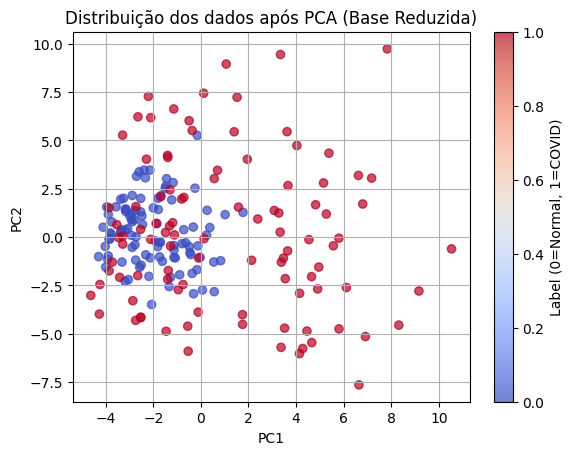

In [11]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", alpha=0.7)
plt.title("Distribuição dos dados após PCA (Base Reduzida)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Label (0=Normal, 1=COVID)")
plt.grid(True)
plt.show()



In [12]:
from sklearn.model_selection import train_test_split

# Divide em 80% treino e 20% validação
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)



In [13]:
n_qubits = 4
n_layers = 3
param_shape = qml.templates.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
params = np.random.uniform(0, np.pi, size=param_shape, requires_grad=True)



In [14]:
from pennylane.optimize import AdamOptimizer
opt = AdamOptimizer(stepsize=0.001)


 # ou stepsize=0.05, se quiser testar


# stepsize define o quanto o parametro será ajustado em cada interação
# quanto maior o stepsize: será ajustado forte o parametro, pode passar do mínimo e ficar oscilando
# quanto menor: demora mais para se chegar ao mínimo, mas tem mais estabilidade

In [15]:
loss_history = []
best_val_acc = 0
patience = 5
patience_counter = 0
best_params = None

steps = 1000
batch_size = 40

for step in range(steps):
    # Seleção do batch
    indices = np.random.choice(len(X_train), batch_size, replace=False)
    X_batch = X_train[indices]
    y_batch = y_train[indices]

    # Otimização
    params = opt.step(lambda v: cost(v, X_batch, y_batch), params)

    # Calcula a loss e salva
    loss = cost(params, X_batch, y_batch)
    loss_history.append(loss)

    if step % 50 == 0:
        # Predições e acurácias
        sample_preds = [circuit(params, x) for x in X_val[:5]]
        print("Sample preds:", np.round(sample_preds, 3))

        acc_train = accuracy(params, X_train, y_train)
        acc_val = accuracy(params, X_val, y_val)
        print(f"Step {step}: Acc Treino = {acc_train:.2%} | Acc Validação = {acc_val:.2%} | Cost batch = {loss:.4f}")

        # EARLY STOPPING
        if acc_val > best_val_acc:
            best_val_acc = acc_val
            patience_counter = 0
            best_params = params.copy()
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping ativado no step {step}! Melhor acc validação: {best_val_acc:.2%}")
            params = best_params  # Restaura os melhores parâmetros
            break


Sample preds: [[ 0.775 -0.115  0.003 -0.112]
 [-0.229 -0.056 -0.049  0.14 ]
 [ 0.077 -0.065 -0.037  0.092]
 [ 0.142 -0.245 -0.148 -0.054]
 [-0.277 -0.231  0.087 -0.047]]
Step 0: Acc Treino = 50.00% | Acc Validação = 55.00% | Cost batch = 0.7478
Sample preds: [[ 0.761 -0.095  0.005 -0.086]
 [-0.249 -0.099 -0.109  0.11 ]
 [ 0.088 -0.096 -0.029  0.104]
 [ 0.167 -0.207 -0.131 -0.05 ]
 [-0.28  -0.237  0.081 -0.025]]
Step 50: Acc Treino = 51.25% | Acc Validação = 55.00% | Cost batch = 0.7067
Sample preds: [[ 0.745 -0.078 -0.001 -0.065]
 [-0.269 -0.127 -0.157  0.073]
 [ 0.09  -0.128 -0.018  0.107]
 [ 0.19  -0.201 -0.123 -0.044]
 [-0.274 -0.246  0.078  0.002]]
Step 100: Acc Treino = 48.75% | Acc Validação = 55.00% | Cost batch = 0.6910
Sample preds: [[ 0.727 -0.048  0.009 -0.034]
 [-0.297 -0.151 -0.193  0.036]
 [ 0.096 -0.166 -0.     0.102]
 [ 0.207 -0.176 -0.104 -0.023]
 [-0.267 -0.249  0.066  0.023]]
Step 150: Acc Treino = 49.38% | Acc Validação = 57.50% | Cost batch = 0.7262
Sample preds: [

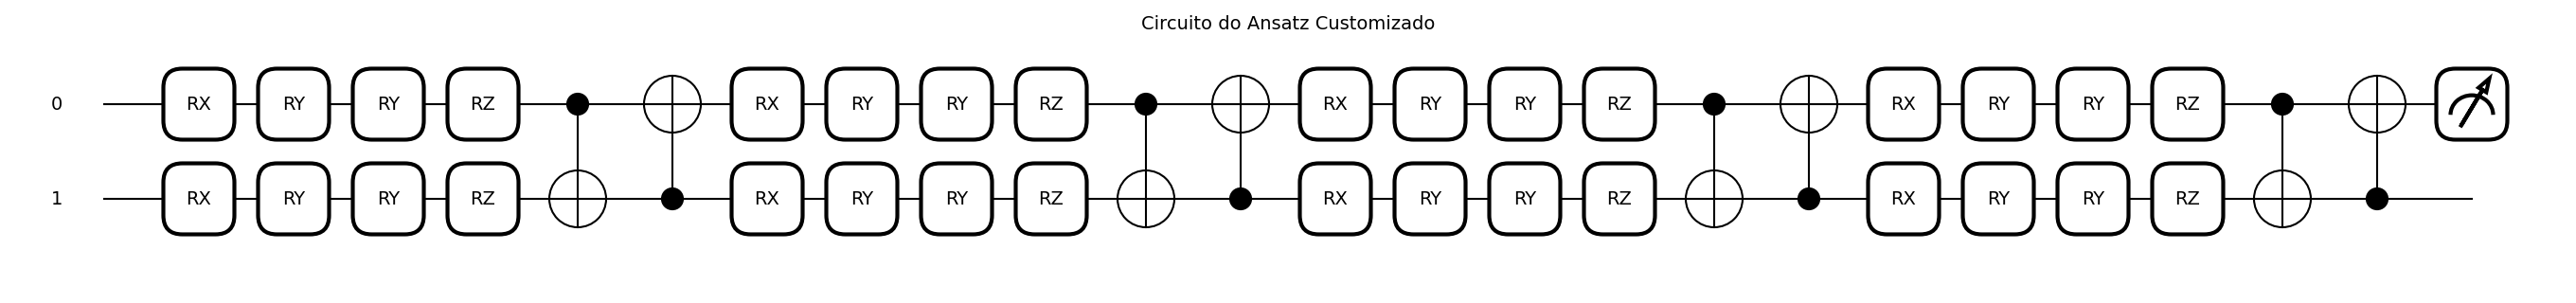

In [16]:
import pennylane as qml
import matplotlib.pyplot as plt

dev = qml.device("default.qubit", wires=2)

@qml.qnode(dev)
def visual_ansatz():
    x = [qml.numpy.pi/4]*4  # valores de entrada simbólicos

    for layer in range(4):  # 4 camadas
        qml.RX(x[0], wires=0)
        qml.RX(x[1], wires=1)
        qml.RY(x[2], wires=0)
        qml.RY(x[3], wires=1)

        qml.RY(layer + 0.1, wires=0)
        qml.RZ(layer + 0.2, wires=0)
        qml.RY(layer + 0.3, wires=1)
        qml.RZ(layer + 0.4, wires=1)

        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[1, 0])

    return qml.expval(qml.PauliZ(0))

fig, ax = qml.draw_mpl(visual_ansatz)()
fig.suptitle("Circuito do Ansatz Customizado", fontsize=14)
fig.savefig("ansatz_circuito.png")  # Arquivo salvo localmente


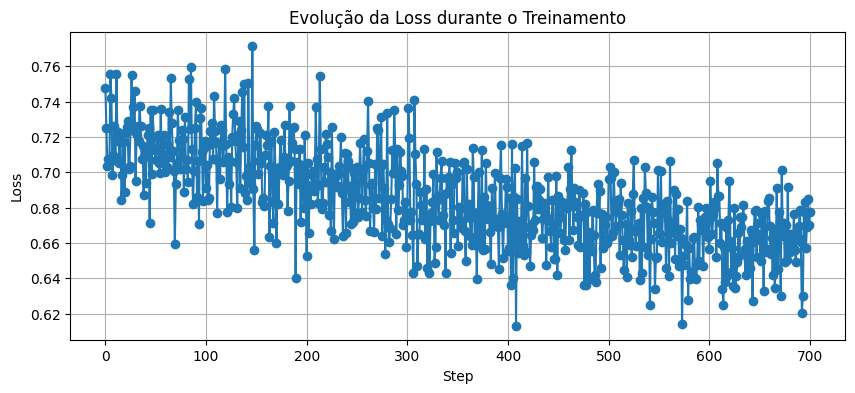

In [17]:
plt.figure(figsize=(10, 4))
plt.plot(loss_history, marker='o')
plt.title("Evolução da Loss durante o Treinamento")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


In [18]:
print(f"Parâmetros finais: {params}")
#parametros finais que utilizam os operadores RY e RX

Parâmetros finais: [[[ 2.90981586  2.16422854  1.14065286]
  [ 0.48772173  0.85640045  1.46837221]
  [ 0.0821188   0.00959416 -0.19977795]
  [ 2.4368586   3.20100948  0.45081904]]

 [[ 2.53034541  2.32298373  1.07414732]
  [ 0.95451626  0.10090155  0.15105197]
  [ 0.34541903  2.69325158  2.77025088]
  [-0.03440324  0.75068814  1.60250339]]

 [[ 0.01742964  0.06951597  3.05491137]
  [ 1.26946482  0.23054506  1.1437443 ]
  [ 2.2530435   2.09574636  0.1045565 ]
  [ 1.41939621  2.29852148  2.80119111]]]


In [19]:
from pennylane import draw

# desenha o QNode completo (ansatz + codificação + medição)
drawer = draw(circuit)
print(drawer(params, X_train[0]))


0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤  <Z>

M0 = 
[-3.14014034  1.42677427 -2.03552443  0.67380395]
M1 = 
[[[ 2.90981586  2.16422854  1.14065286]
  [ 0.48772173  0.85640045  1.46837221]
  [ 0.0821188   0.00959416 -0.19977795]
  [ 2.4368586   3.20100948  0.45081904]]

 [[ 2.53034541  2.32298373  1.07414732]
  [ 0.95451626  0.10090155  0.15105197]
  [ 0.34541903  2.69325158  2.77025088]
  [-0.03440324  0.75068814  1.60250339]]

 [[ 0.01742964  0.06951597  3.05491137]
  [ 1.26946482  0.23054506  1.1437443 ]
  [ 2.2530435   2.09574636  0.1045565 ]
  [ 1.41939621  2.29852148  2.80119111]]]


In [20]:
np.save("melhores_params_72.5.npy", best_params)


In [21]:
final_acc_train = accuracy(best_params, X_train, y_train)
final_acc_val = accuracy(best_params, X_val, y_val)

print(f"Acurácia final treino: {final_acc_train:.2%}")
print(f"Acurácia final validação: {final_acc_val:.2%}")


Acurácia final treino: 59.38%
Acurácia final validação: 72.50%


In [23]:
import os

# Cria a pasta se não existir
os.makedirs("PARAMS_SALVOS", exist_ok=True)

# Agora pode salvar sem erro
np.save("PARAMS_SALVOS/best_params_72_5.npy", best_params)


In [24]:
# se ainda não salvou:
np.save("PARAMS_SALVOS/best_params_72_5.npy", best_params)
